# Ablation: every model family converges to the same ceiling

**Question.** Can any model or setting beat the gradient-boosting baseline, or is performance limited by the data?

**Setup** (`run.py`, results in `results/`)
- Label `SCREENING_12M_FLAG` (19.3% positive). Official patient-level split: fit on **train**, choose settings on
  **val**, report on **test**.
- **Capacity study:** 9 model families from tiny to huge (and deliberately overfitting) settings, 38 fits, all on
  the full train split and the 19 raw features.
- **Learning curve:** logistic regression, decision tree, gradient boosting and an MLP trained on 1%–100% of the
  train women.
- **Feature study:** the same models on the 96 engineered features of the prepared data instead of the 19 raw ones.
- **Train ROC AUC** (on up to 200k of the rows the model was fitted on) shows how much a model memorises.
  A large train−test gap means overfitting.
- **Best per family:** the setting with the best *val* ROC AUC. Its *test* ROC AUC gap to the overall best has a
  95% bootstrap interval that resamples women (with all their invitations).

The question is whether the families meet at the same test ROC AUC, and whether more capacity or more data
still moves it.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


RESULTS = Path("results")
res = pd.read_csv(RESULTS / "ablation.csv")
best = pd.read_csv(RESULTS / "best_per_family.csv")
cap = res[res.study == "capacity"]

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, INK2, GRID = "#a3a29d", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": INK2,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "legend.frameon": False,
    }
)
TOP = best.test_roc_auc.max()
print(
    f"{len(res)} fits ({res.study.value_counts().to_dict()}), {res.fit_seconds.sum() / 60:.0f} min of fitting"
)
print(f"Best test ROC AUC: {TOP:.4f} ({best.iloc[0].family}, {best.iloc[0].setting})")

57 fits ({'capacity': 38, 'learning curve': 16, 'features': 3}), 15 min of fitting
Best test ROC AUC: 0.8413 (gradient boosting, 63 leaves, lr .05, 1000 iter)


## 1. Best setting of each family

In [ ]:
table = best.set_index("family")[
    [
        "setting",
        "val_roc_auc",
        "test_roc_auc",
        "test_pr_auc",
        "train_roc_auc",
        "gap_to_best",
        "gap_low",
        "gap_high",
        "fit_seconds",
    ]
]
table.style.format(
    {
        "val_roc_auc": "{:.4f}",
        "test_roc_auc": "{:.4f}",
        "test_pr_auc": "{:.4f}",
        "train_roc_auc": "{:.4f}",
        "gap_to_best": "{:+.4f}",
        "gap_low": "{:+.4f}",
        "gap_high": "{:+.4f}",
        "fit_seconds": "{:,}",
    }
)

,setting,val_roc_auc,test_roc_auc,test_pr_auc,train_roc_auc,gap_to_best,gap_low,gap_high,fit_seconds
family,,,,,,,,,
gradient boosting,"63 leaves, lr .05, 1000 iter",0.8389,0.8413,0.5810,0.8483,+0.0000,+0.0000,+0.0000,11
MLP,"3 layers, strong L2 (alpha 1e-2)",0.8380,0.8404,0.5792,0.8431,-0.0009,-0.0013,-0.0005,115
random forest,"depth 16, leaf 20",0.8377,0.8400,0.5778,0.8479,-0.0013,-0.0018,-0.0009,13
decision tree,depth 12,0.8344,0.8373,0.5710,0.8394,-0.0040,-0.0046,-0.0035,6
logistic regression,splines (additive),0.8331,0.8346,0.5619,0.8336,-0.0067,-0.0073,-0.0062,11
kNN (50k rows),k=250,0.8295,0.8314,0.5635,0.8342,-0.0100,-0.0107,-0.0092,0
few-feature LR,5 features,0.8145,0.8181,0.5273,0.8161,-0.0232,-0.0243,-0.0221,1
naive Bayes,smoothing 1e-2,0.7973,0.7998,0.4710,0.7979,-0.0415,-0.0428,-0.0403,3
constant,base rate,0.5000,0.5000,0.1929,0.5000,-0.3413,-0.3435,-0.3388,0


## 2. All 38 settings

Each dot is one setting, at its test ROC AUC. Blue = the setting chosen on val; gray = the others.
The band marks the best test ROC AUC − 0.005, a difference too small to matter in practice.

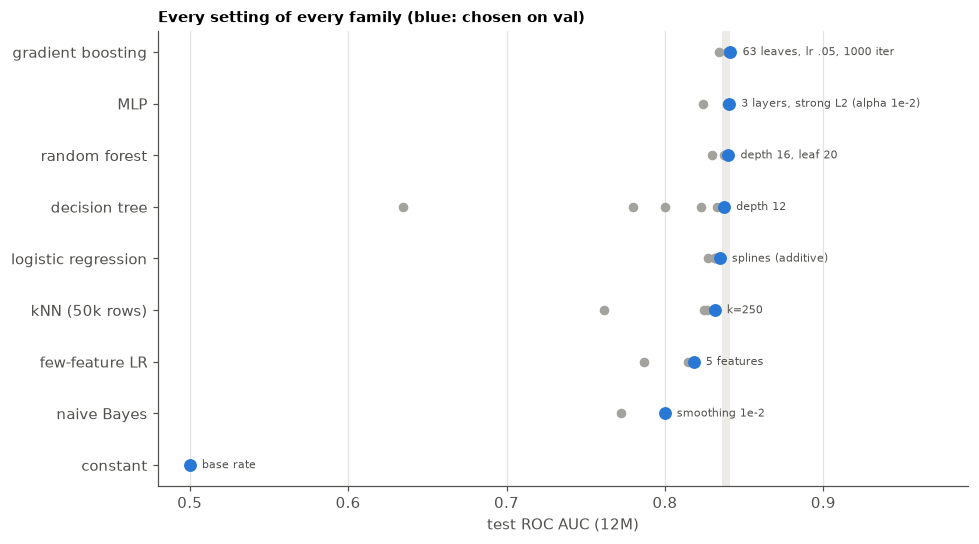

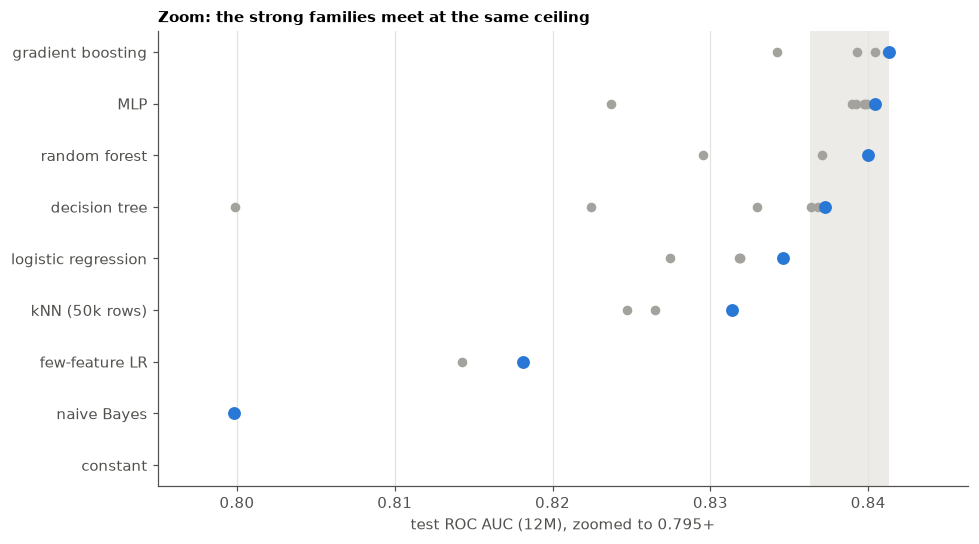

In [ ]:
fams = best.family.tolist()[::-1]  # weakest at the bottom
fig, ax = plt.subplots(figsize=(9, 0.45 * len(fams) + 1))
ax.axvspan(TOP - 0.005, TOP, color=GRID, alpha=0.7, lw=0)
for i, fam in enumerate(fams):
    s = cap[cap.family == fam]
    chosen = best.set_index("family").loc[fam, "setting"]
    other = s[s.setting != chosen]
    ax.scatter(other.test_roc_auc, np.full(len(other), i), color=GRAY, s=28, zorder=3)
    pick = s[s.setting == chosen]
    ax.scatter(pick.test_roc_auc, [i], color=BLUE, s=55, zorder=4)
    ax.annotate(
        chosen,
        (pick.test_roc_auc.iloc[0], i),
        xytext=(8, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=7,
        color=INK2,
    )
ax.set_yticks(range(len(fams)), fams)
ax.grid(axis="y", visible=False)
ax.set_xlim(0.48, TOP + 0.15)  # room for the labels
ax.set_xlabel("test ROC AUC (12M)")
ax.set_title("Every setting of every family (blue: chosen on val)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 0.45 * len(fams) + 1))  # zoom on the top
ax.axvspan(TOP - 0.005, TOP, color=GRID, alpha=0.7, lw=0)
for i, fam in enumerate(fams):
    s = cap[cap.family == fam]
    chosen = best.set_index("family").loc[fam, "setting"]
    ax.scatter(
        s[s.setting != chosen].test_roc_auc,
        np.full((s.setting != chosen).sum(), i),
        color=GRAY,
        s=28,
        zorder=3,
    )
    ax.scatter(s[s.setting == chosen].test_roc_auc, [i], color=BLUE, s=55, zorder=4)
ax.set_yticks(range(len(fams)), fams)
ax.grid(axis="y", visible=False)
ax.set_xlim(0.795, TOP + 0.005)
ax.set_xlabel("test ROC AUC (12M), zoomed to 0.795+")
ax.set_title("Zoom: the strong families meet at the same ceiling")
plt.tight_layout()
plt.show()

## 3. More capacity: test ROC AUC levels off while train ROC AUC keeps rising

Settings are ordered from small to large within each family. Solid = test, dashed = train (the rows the model
was fitted on); the dotted line is the overall best test ROC AUC. When the dashed line goes up and the solid line
does not, the extra capacity only memorises the training data.

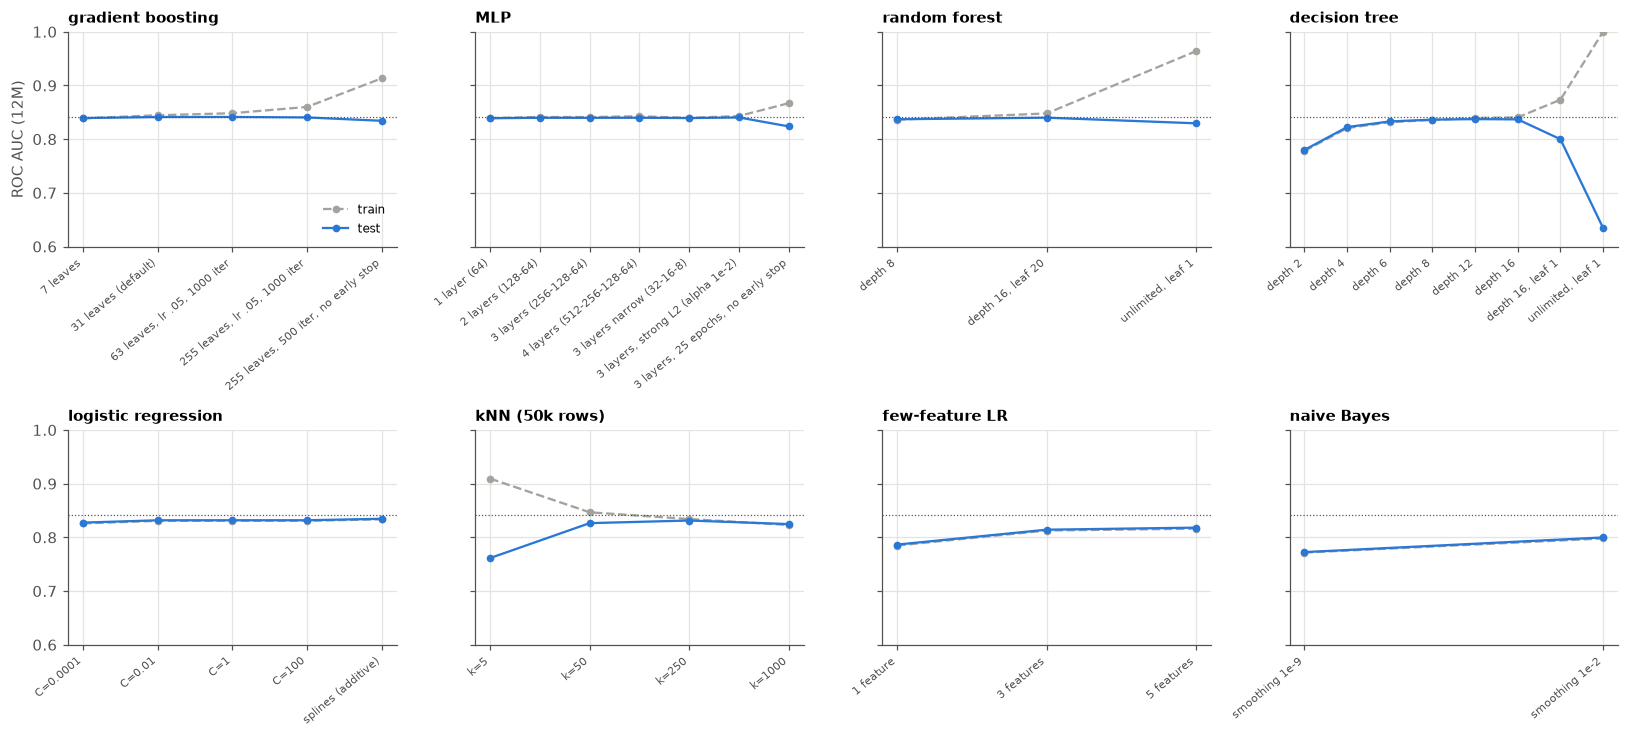

In [ ]:
families = [f for f in best.family if f != "constant"]
ncol = 4
nrow = int(np.ceil(len(families) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.4 * nrow), sharey=True)
for ax, fam in zip(axes.flat, families, strict=False):
    s = cap[cap.family == fam]
    xs = np.arange(len(s))
    ax.plot(xs, s.train_roc_auc, color=GRAY, ls="--", marker="o", ms=4, label="train")
    ax.plot(xs, s.test_roc_auc, color=BLUE, marker="o", ms=4, label="test")
    ax.axhline(TOP, color=INK2, lw=0.8, ls=":")
    ax.set_xticks(xs, s.setting, rotation=40, ha="right", fontsize=7)
    ax.set_title(fam)
    ax.set_ylim(0.60, 1.0)
for ax in axes.flat[len(families) :]:
    ax.set_visible(False)
axes.flat[0].legend(loc="lower right", fontsize=8)
axes.flat[0].set_ylabel("ROC AUC (12M)")
plt.tight_layout()
plt.show()

## 4. More data: learning curves flatten at the same level

Test ROC AUC (solid) and train ROC AUC (dashed) by number of training rows. Training subsets are nested samples of
women (1%, 3%, 10%, 30%, 100%).

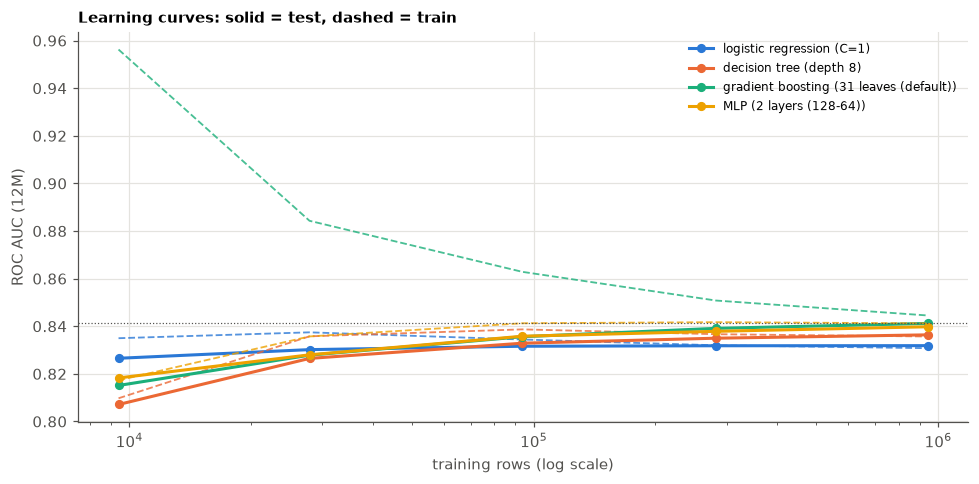

,1%,3%,10%,30%,100%
family,,,,,
MLP,0.8183,0.8280,0.8358,0.8379,0.8398
decision tree,0.8071,0.8265,0.8329,0.8350,0.8364
gradient boosting,0.8151,0.8279,0.8356,0.8391,0.8412
logistic regression,0.8265,0.8302,0.8316,0.8318,0.8319


In [ ]:
lc = pd.concat(
    [
        res[res.study == "learning curve"],
        cap.merge(
            res[res.study == "learning curve"][["family", "setting"]].drop_duplicates()
        ),
    ]
)
colors = {
    "logistic regression": BLUE,
    "decision tree": ORANGE,
    "gradient boosting": AQUA,
    "MLP": YELLOW,
}
fig, ax = plt.subplots(figsize=(9, 4.5))
for fam, color in colors.items():
    s = lc[lc.family == fam].sort_values("train_rows")
    ax.plot(
        s.train_rows,
        s.test_roc_auc,
        color=color,
        marker="o",
        ms=5,
        lw=2,
        label=f"{fam} ({s.setting.iloc[0]})",
    )
    ax.plot(s.train_rows, s.train_roc_auc, color=color, ls="--", lw=1.2, alpha=0.8)
ax.axhline(TOP, color=INK2, lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xlabel("training rows (log scale)")
ax.set_ylabel("ROC AUC (12M)")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Learning curves: solid = test, dashed = train")
plt.tight_layout()
plt.show()

pivot = lc.pivot_table(index="family", columns="train_fraction", values="test_roc_auc")
pivot.columns = [f"{c:.0%}" for c in pivot.columns]
pivot.style.format("{:.4f}")

## 5. More features: 96 engineered vs 19 raw

In [ ]:
feat = res[res.study == "features"].merge(
    cap, on=["family", "setting"], suffixes=("_engineered", "_raw")
)
feat = feat.assign(gain=feat.test_roc_auc_engineered - feat.test_roc_auc_raw)
feat.set_index(["family", "setting"])[
    ["test_roc_auc_raw", "test_roc_auc_engineered", "gain"]
].style.format(
    {
        "test_roc_auc_raw": "{:.4f}",
        "test_roc_auc_engineered": "{:.4f}",
        "gain": "{:+.4f}",
    }
)

,,test_roc_auc_raw,test_roc_auc_engineered,gain
family,setting,,,
logistic regression,C=1,0.8319,0.8351,+0.0032
gradient boosting,31 leaves (default),0.8412,0.8423,+0.0011
MLP,2 layers (128-64),0.8398,0.8416,+0.0019


## 6. Conclusions

**1. All capable model families meet at the same ceiling, test ROC AUC ≈ 0.84.** Best setting per family (chosen on val):

| family | test ROC AUC | gap to best |
|---|---|---|
| gradient boosting | 0.8413 | — |
| MLP | 0.8404 | −0.0009 |
| random forest | 0.8400 | −0.0013 |
| single decision tree | 0.8373 | −0.0040 |
| additive (spline) logistic regression | 0.8346 | −0.0067 |
| kNN (on only 50k rows) | 0.8314 | −0.0100 |

These are very different model classes: boosted and bagged trees, a neural network, one tree, an additive
model, nearest neighbours. They all end within 0.01 of each other, and the three flexible ones within 0.0013.
The bootstrap intervals show the gaps are real but tiny. No model class has an advantage that would matter in
practice.

**2. More capacity does not raise the ceiling; it only memorises the training data.**
- Gradient boosting from 7 to 63 leaves: test 0.8393 → 0.8413 (+0.002), then down to 0.8404 at 255 leaves.
  Without early stopping: train 0.913, test 0.834.
- MLP from 1 to 4 hidden layers: test 0.8390 → 0.8399 (+0.001), at 6× the fit time.
  Without early stopping: train 0.867, test 0.824.
- Decision tree: test peaks at depth 12 (0.8373). Fully grown: train **1.000**, test **0.635**.
- Random forest: depth 16 best (0.8400). Fully grown: train 0.964, test 0.830.
- Logistic regression is insensitive to regularisation (C = 0.01 … 100: test 0.8318–0.8319). Letting each
  feature bend (splines) adds only +0.0027.

**3. More data does not raise the ceiling either.** Going from 30% to 100% of the train women (282k → 942k rows):
logistic regression +0.0001, decision tree +0.0014, MLP +0.0019, gradient boosting +0.0021. The curves are flat,
and train ROC AUC falls to meet test ROC AUC (gradient boosting: train 0.956 on 1% of the data → 0.845 on 100%).
When the training score drops to the test score, the model can no longer even fit its own training data much
better: the remaining errors are noise *with respect to these features*.

**4. More features do not raise it either.** The 96 engineered features (history, spatial, dates, flags) add
+0.001 to +0.003 (best overall: gradient boosting on engineered features, 0.8423).

**5. A handful of features already gets most of the way.** Logistic regression on 3 features
(`PRIOR_INVITATION_COUNT`, `GYN_PREVENTION_24M_CNT`, `MONTHS_SINCE_LAST_SCREEN`) reaches 0.814. With 5 features it
reaches 0.818, about 93% of the way from chance (0.5) to the best model (0.841).

**Conclusion.** Model class, capacity, regularisation, training-set size and feature engineering all lead to the
same test ROC AUC of about 0.84. The limit is the information in the data, not the model. To predict
better, VZP would need *new* information about each woman. Examples: how and when the invitation was delivered
and whether it was read, reminders, the GP's own screening practice, socio-economic context, individual travel
time, past missed appointments.

**Caveats.** 12M label only (the 3M and 6M models behave the same in `compare.py`). kNN is fitted on a 50k-row
sample because of prediction cost. Random forests use 25% of rows per tree. The settings are broad but not an
exhaustive search. The convergence across families is what makes the case, not any single setting.